In [2]:
import os
import glob
import shutil
import random
import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

PLAN = "plan.png"
SYMBOL_DIR = "symbols"
OUT_DIR = "synth"
NUM_IMAGES = 2500

TARGET_W = 5800
TILE = 1024
OVERLAP = 256
IMG = TILE

In [3]:
TURNS = {90: Image.ROTATE_90, 180: Image.ROTATE_180, 270: Image.ROTATE_270}


def trim(img):
    a = np.array(img.getchannel("A"))
    ys, xs = np.where(a > 40)
    return img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))


def load_symbols():
    out = []
    for i, p in enumerate(sorted(glob.glob(os.path.join(SYMBOL_DIR, "*.png")))):
        name = os.path.splitext(os.path.basename(p))[0]
        arr = np.array(Image.open(p).convert("RGB")).astype(float)
        alpha = np.clip(255 - arr.mean(axis=2), 0, 255).astype(np.uint8)
        rgba = np.zeros(alpha.shape + (4,), dtype=np.uint8)
        rgba[:, :, 3] = alpha
        out.append((i, name, trim(Image.fromarray(rgba, "RGBA"))))
    return out


def calibrate(symbols):
    plan = cv2.imread(PLAN)
    f = TARGET_W / plan.shape[1]
    plan = cv2.resize(plan, None, fx=f, fy=f, interpolation=cv2.INTER_AREA).max(axis=2)
    H, W = plan.shape
    legend = plan[int(0.80 * H):, : int(0.33 * W)]
    scales, matches = {}, []
    for cid, name, sym in symbols:
        tmpl = 255 - np.array(sym.getchannel("A"))

        def score(s):
            t = cv2.resize(tmpl, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
            if min(t.shape) < 10 or t.shape[0] >= legend.shape[0] or t.shape[1] >= legend.shape[1]:
                return -1.0
            return float(cv2.matchTemplate(legend, t, cv2.TM_CCOEFF_NORMED).max())

        best = max(np.geomspace(0.04, 1.5, 80), key=score)
        best = max(np.geomspace(best / 1.06, best * 1.06, 21), key=score)
        scales[name] = float(best)
        matches.append(score(best))
    return scales, matches


symbols = load_symbols()
scales, matches = calibrate(symbols)
SCALE = float(np.median(list(scales.values())))

print("per-symbol scale estimates:", {k: round(v, 3) for k, v in scales.items()})
print("using median scale:", round(SCALE, 3), "  lowest match score:", round(min(matches), 2))
print("\nsymbol sizes at this scale:")
for cid, name, sym in symbols:
    print(f"  {name:18s} {round(sym.size[0] * SCALE)} x {round(sym.size[1] * SCALE)}")

per-symbol scale estimates: {'ceil_light': 0.291, 'dimmer_switch': 0.288, 'duplex_outlet': 0.289, 'recessed_light': 0.293, 'smoke_detector': 0.289, 'switch': 0.324, 'three_way': 0.288, 'wall_light': 0.289}
using median scale: 0.289   lowest match score: 0.96

symbol sizes at this scale:
  ceil_light         71 x 72
  dimmer_switch      38 x 46
  duplex_outlet      106 x 71
  recessed_light     71 x 72
  smoke_detector     69 x 60
  switch             19 x 32
  three_way          35 x 47
  wall_light         99 x 71


In [4]:
WORDS = [
    "Bedroom", "Kitchen", "Laundry", "Closet", "Master Bathroom", "Living Room",
    "Dining Room", "Entry", "Pantry", "Breakfast Area", "To Garage", "Bathroom",
    "CFGI", "240V", "fridge", "Scale 1:50", "Sheet", "Document status",
    "Date of issue", "Created", "Approved", "Responsible dep.", "Technical reference",
    "Symbols Used on Floor Plan", "ceiling light fixture", "recessed light fixture",
    "smoke detector", "duplex receptacle outlet", "switch", "three-way switch",
    "dimmer switch", "wall mounted light", "House Wiring Diagram", "Garage", "Hall",
]
FONT_NAMES = ["DejaVuSans.ttf", "LiberationSans-Regular.ttf", "Arial.ttf"]


def get_font(size):
    for n in FONT_NAMES:
        try:
            return ImageFont.truetype(n, size)
        except OSError:
            pass
    return ImageFont.load_default()


def make_instance(sym):
    k = SCALE * random.uniform(0.9, 1.1)
    w, h = sym.size
    size = (max(4, round(w * k)), max(4, round(h * k)))
    s = sym.resize(size, Image.BOX if k < 1 else Image.BICUBIC)
    turn = random.choice([0, 0, 90, 180, 270])
    if turn:
        s = s.transpose(TURNS[turn])
    return trim(s)


def draw_grid(draw):
    step = random.choice([32, 40, 48])
    for x in range(0, IMG, step):
        draw.line([(x, 0), (x, IMG)], fill=(235, 235, 235), width=1)
    for y in range(0, IMG, step):
        draw.line([(0, y), (IMG, y)], fill=(235, 235, 235), width=1)


def draw_fills(draw):
    for _ in range(random.randint(0, 3)):
        x0, y0 = random.randint(0, IMG - 150), random.randint(0, IMG - 150)
        x1, y1 = x0 + random.randint(100, 500), y0 + random.randint(60, 300)
        col = random.choice([(255, 204, 153), (204, 255, 255), (255, 255, 0)])
        draw.rectangle([x0, y0, x1, y1], fill=col, outline=(40, 40, 40), width=2)


def draw_walls(draw):
    for _ in range(random.randint(1, 3)):
        x0, y0 = random.randint(-100, IMG - 250), random.randint(-100, IMG - 250)
        x1, y1 = x0 + random.randint(250, 800), y0 + random.randint(250, 800)
        t = random.randint(12, 22)
        draw.rectangle([x0, y0, x1, y1], outline=(21, 84, 166), width=t)
        if random.random() < 0.6:
            gx = random.randint(x0 + 40, max(x0 + 41, x1 - 120))
            draw.rectangle([gx, y0 - 2, gx + random.randint(50, 110), y0 + t + 2], fill=(255, 255, 255))


def draw_dashed_curve(draw):
    p = [(random.randint(0, IMG), random.randint(0, IMG)) for _ in range(4)]
    pts = []
    for t in np.linspace(0, 1, 220):
        x = (1 - t) ** 3 * p[0][0] + 3 * (1 - t) ** 2 * t * p[1][0] + 3 * (1 - t) * t ** 2 * p[2][0] + t ** 3 * p[3][0]
        y = (1 - t) ** 3 * p[0][1] + 3 * (1 - t) ** 2 * t * p[1][1] + 3 * (1 - t) * t ** 2 * p[2][1] + t ** 3 * p[3][1]
        pts.append((x, y))
    w = random.choice([3, 4])
    for i in range(0, len(pts) - 1, 12):
        draw.line(pts[i:i + 8], fill=(128, 0, 128), width=w)


def draw_clutter(draw):
    for _ in range(random.randint(2, 8)):
        kind = random.choice(["arc", "sink", "line", "stairs", "box"])
        x, y = random.randint(0, IMG - 250), random.randint(0, IMG - 250)
        if kind == "arc":
            r = random.randint(40, 110)
            draw.arc([x, y, x + 2 * r, y + 2 * r], 180, 270, fill=(30, 30, 30), width=2)
            draw.line([x + r, y + r, x + 2 * r, y + r], fill=(30, 30, 30), width=3)
        elif kind == "sink":
            w, h = random.randint(50, 130), random.randint(40, 100)
            draw.ellipse([x, y, x + w, y + h], fill=(204, 255, 255), outline=(40, 40, 40), width=2)
            if random.random() < 0.6:
                r = random.randint(8, 18)
                draw.ellipse([x + w // 2 - r, y + h // 2 - r, x + w // 2 + r, y + h // 2 + r],
                             outline=(40, 40, 40), width=2)
        elif kind == "line":
            draw.line([x, y, x + random.randint(-200, 200), y + random.randint(-200, 200)],
                      fill=(30, 30, 30), width=2)
        elif kind == "stairs":
            gap = random.randint(18, 30)
            for i in range(random.randint(4, 8)):
                draw.line([x, y + i * gap, x + random.randint(120, 220), y + i * gap],
                          fill=(40, 80, 200), width=2)
        else:
            draw.rectangle([x, y, x + random.randint(20, 90), y + random.randint(20, 90)],
                           outline=(30, 30, 30), width=2)


def draw_text(img, draw, forbidden):
    for _ in range(random.randint(3, 12)):
        word = random.choice(WORDS)
        font = get_font(random.choice([random.randint(16, 46), random.randint(40, 85)]))
        color = random.choice([(0, 0, 0)] * 6 + [(255, 0, 255), (0, 0, 200)])
        bb = draw.textbbox((0, 0), word, font=font)
        tw, th = bb[2] - bb[0], bb[3] - bb[1]
        x = random.randint(0, max(0, IMG - tw))
        y = random.randint(0, max(0, IMG - th))
        if random.random() < 0.15:
            tmp = Image.new("RGBA", (tw + 8, th + 8), (0, 0, 0, 0))
            ImageDraw.Draw(tmp).text((4 - bb[0], 4 - bb[1]), word, font=font, fill=color + (255,))
            tmp = tmp.rotate(90, expand=True)
            img.paste(tmp, (x, y), tmp)
            forbidden.append((x, y, x + tmp.size[0], y + tmp.size[1]))
        else:
            draw.text((x - bb[0], y - bb[1]), word, font=font, fill=color)
            forbidden.append((x, y, x + tw, y + th))


def hit(a, b, pad=6):
    return not (a[2] + pad < b[0] or b[2] + pad < a[0] or a[3] + pad < b[1] or b[3] + pad < a[1])


def generate_one(symbols):
    img = Image.new("RGB", (IMG, IMG), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    if random.random() < 0.25:
        draw_grid(draw)
    draw_fills(draw)
    draw_walls(draw)
    draw_clutter(draw)
    for _ in range(random.randint(0, 4)):
        draw_dashed_curve(draw)
    forbidden = []
    draw_text(img, draw, forbidden)

    n = 0 if random.random() < 0.08 else random.randint(2, 18)
    placed, labels, tries = [], [], 0
    while len(labels) < n and tries < n * 25:
        tries += 1
        cid, name, sym = random.choice(symbols)
        s = make_instance(sym)
        sw, sh = s.size
        if sw >= IMG or sh >= IMG:
            continue
        x, y = random.randint(0, IMG - sw), random.randint(0, IMG - sh)
        box = (x, y, x + sw, y + sh)
        if any(hit(box, b) for b in placed) or any(hit(box, b, 2) for b in forbidden):
            continue
        img.paste(s, (x, y), s)
        placed.append(box)
        labels.append(f"{cid} {(x + sw / 2) / IMG:.6f} {(y + sh / 2) / IMG:.6f} {sw / IMG:.6f} {sh / IMG:.6f}")
    return img, labels, placed

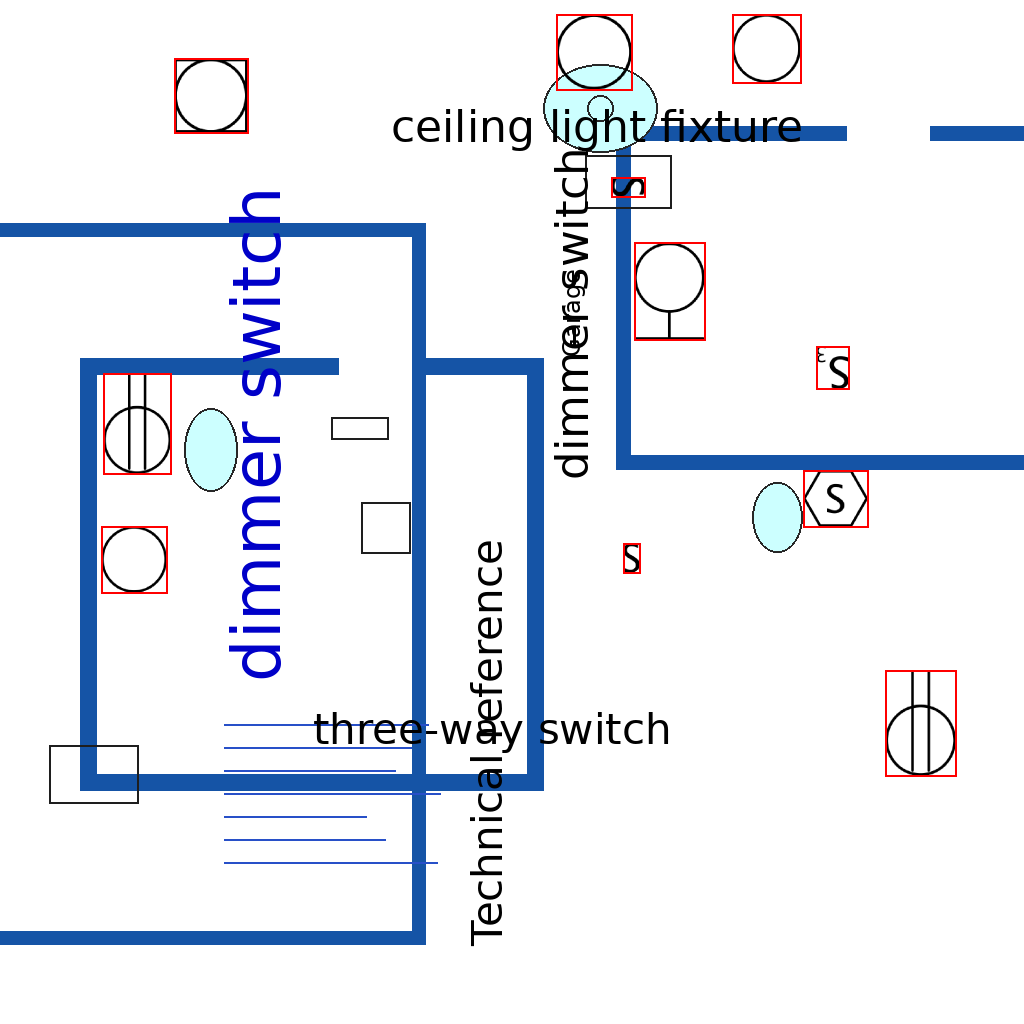

In [9]:
# Preview
img, labels, placed = generate_one(symbols)
chk = img.copy()
d = ImageDraw.Draw(chk)
for b in placed:
    d.rectangle(b, outline=(255, 0, 0), width=2)
chk

In [10]:
shutil.rmtree(OUT_DIR, ignore_errors=True)


def build(split, count):
    img_dir = os.path.join(OUT_DIR, "images", split)
    lbl_dir = os.path.join(OUT_DIR, "labels", split)
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    for i in range(count):
        img, labels, placed = generate_one(symbols)
        img.save(os.path.join(img_dir, f"{split}_{i:05d}.png"))
        with open(os.path.join(lbl_dir, f"{split}_{i:05d}.txt"), "w") as f:
            f.write("\n".join(labels))
        if i % 300 == 0:
            print(split, i, "/", count)


build("train", int(NUM_IMAGES * 0.9))
build("val", int(NUM_IMAGES * 0.1))

names = [s[1] for s in symbols]
with open("data.yaml", "w") as f:
    f.write(f"path: {os.path.abspath(OUT_DIR)}\ntrain: images/train\nval: images/val\n\nnames:\n")
    for i, n in enumerate(names):
        f.write(f"  {i}: {n}\n")
print("classes:", names)

train 0 / 2250
train 300 / 2250
train 600 / 2250
train 900 / 2250
train 1200 / 2250
train 1500 / 2250
train 1800 / 2250
train 2100 / 2250
val 0 / 250
classes: ['ceil_light', 'dimmer_switch', 'duplex_outlet', 'recessed_light', 'smoke_detector', 'switch', 'three_way', 'wall_light']


### checking annotation

from disk: synth/images/train/train_00203.png


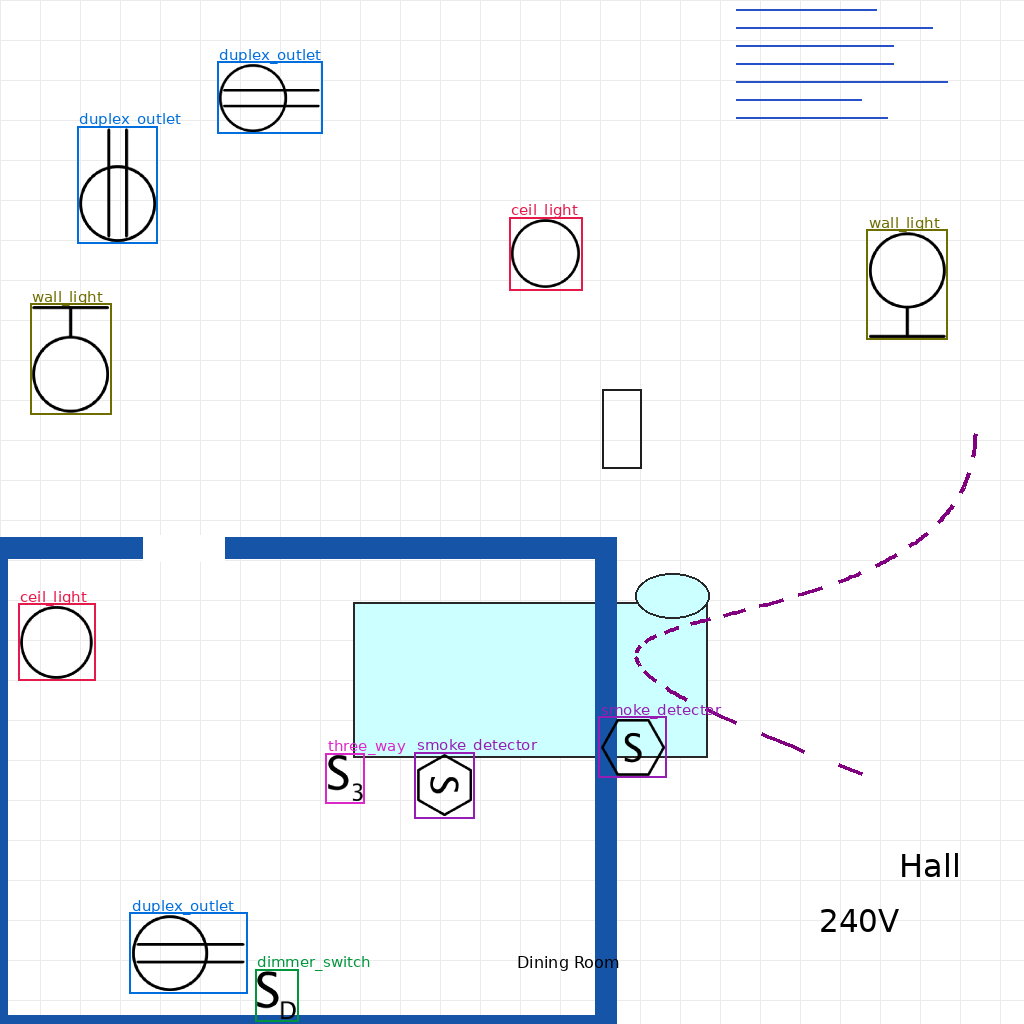


11 symbols in this image
class               center x  center y   width  height
wall_light               907       285      77     106
wall_light                71       359      77     107
ceil_light               546       254      69      69
duplex_outlet            270        98     101      68
three_way                345       778      35      46
duplex_outlet            117       185      77     114
smoke_detector           444       785      55      62
duplex_outlet            188       953     113      76
dimmer_switch            277       995      39      48
smoke_detector           633       747      64      57
ceil_light                57       642      73      73

raw label lines (class  x_center  y_center  width  height, all 0 to 1):
  7 0.886230 0.278320 0.075195 0.103516
  7 0.068848 0.351074 0.075195 0.104492
  0 0.532715 0.247559 0.067383 0.067383
  2 0.263184 0.095703 0.098633 0.066406
  6 0.337402 0.759766 0.034180 0.044922


In [18]:
PALETTE = [(230, 25, 75), (0, 150, 60), (0, 110, 220), (240, 120, 0),
           (150, 30, 180), (0, 190, 190), (220, 40, 200), (110, 110, 0)]


def draw_labels(img, label_lines, names):
    out = img.copy()
    d = ImageDraw.Draw(out)
    font = get_font(15)
    W, H = out.size
    rows = []
    for line in label_lines:
        if not line.strip():
            continue
        cid, xc, yc, bw, bh = line.split()
        cid = int(cid)
        xc, yc, bw, bh = float(xc) * W, float(yc) * H, float(bw) * W, float(bh) * H
        x0, y0, x1, y1 = xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2
        col = PALETTE[cid % len(PALETTE)]
        d.rectangle([x0 - 2, y0 - 2, x1 + 2, y1 + 2], outline=col, width=2)
        d.text((x0, max(0, y0 - 18)), names[cid], fill=col, font=font)
        rows.append((names[cid], round(xc), round(yc), round(bw), round(bh)))
    return out, rows


def show_random(source="auto", split="train"):
    names = [s[1] for s in symbols]
    files = sorted(glob.glob(os.path.join(OUT_DIR, "images", split, "*.png")))
    if source == "disk" or (source == "auto" and files):
        p = random.choice(files)
        img = Image.open(p).convert("RGB")
        lbl_path = os.path.join(OUT_DIR, "labels", split, os.path.basename(p)[:-4] + ".txt")
        lines = open(lbl_path).read().splitlines()
        print("from disk:", p)
    else:
        img, lines, placed = generate_one(symbols)
        print("fresh sample (not saved)")
    out, rows = draw_labels(img, lines, names)
    display(out)
    print(f"\n{len(rows)} symbols in this image")
    print(f"{'class':18s}{'center x':>10s}{'center y':>10s}{'width':>8s}{'height':>8s}")
    for r in rows:
        print(f"{r[0]:18s}{r[1]:>10d}{r[2]:>10d}{r[3]:>8d}{r[4]:>8d}")
    print("\nraw label lines (class  x_center  y_center  width  height, all 0 to 1):")
    for line in lines[:5]:
        print(" ", line)


show_random()

In [19]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="data.yaml",
    epochs=30,
    imgsz=TILE,
    batch=8,
    device=0,
    project=os.path.abspath("runs"),
    name="symbols",
    fliplr=0.0,
    degrees=0.0,
    scale=0.3,
)

BEST = str(model.trainer.best)
print("best weights:", BEST)

Ultralytics 8.4.173 🚀 Python-3.11.15 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5070, 11771MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=symbols, nbs=64, nms=None, opset=None, optimize=False, optimizer

#### CHeck result on Validation Set

image: synth/images/val/val_00232.png


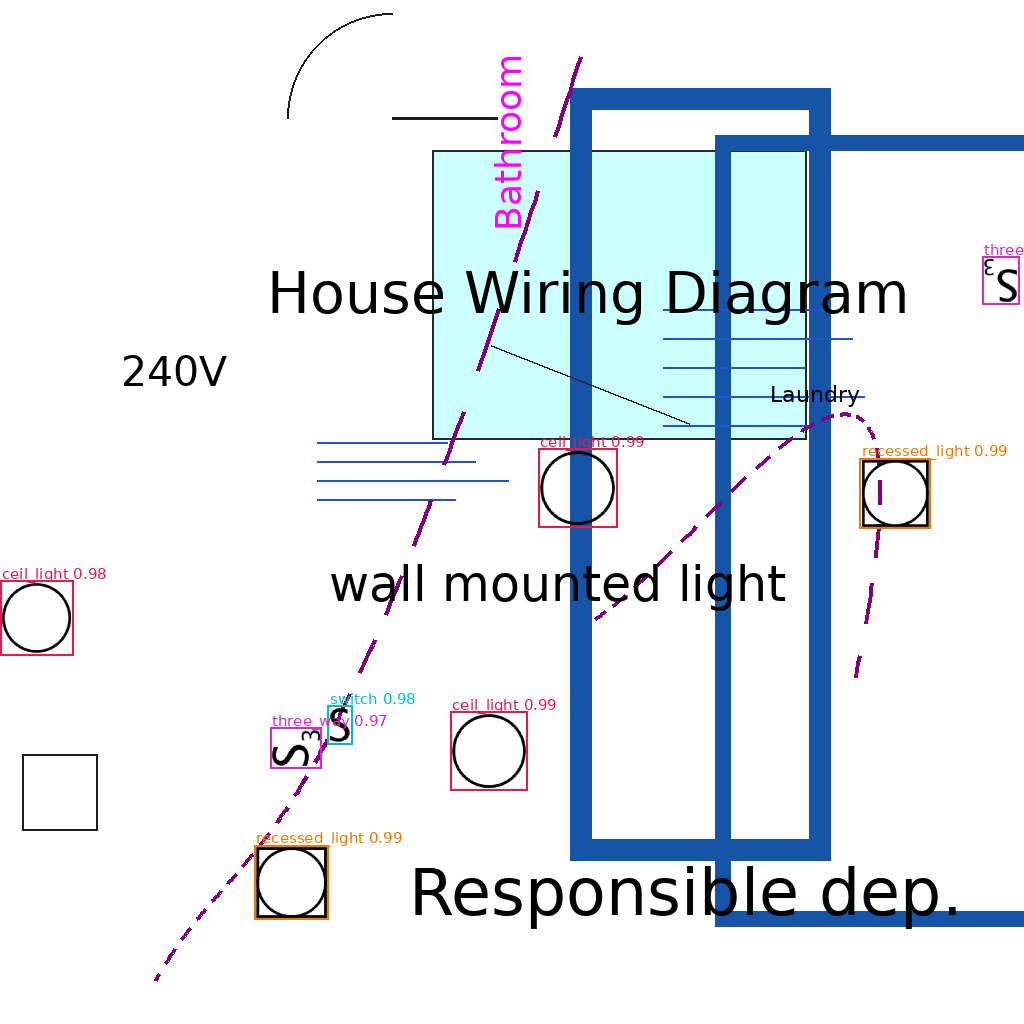


correct 8   false alarms 0   missed 0   (same class and box overlap of at least 0.5)

class               truth  found
ceil_light              3      3
dimmer_switch           0      0
duplex_outlet           0      0
recessed_light          2      2
smoke_detector          0      0
switch                  1      1
three_way               2      2
wall_light              0      0

predictions, least confident first:
class               conf  center x  center y  width  height
three_way           0.97       296       748     48      36
switch              0.98       340       725     20      34
three_way           0.98      1001       280     33      43
ceil_light          0.98        37       618     69      70
recessed_light      0.99       895       493     67      67
recessed_light      0.99       292       882     71      71
ceil_light          0.99       578       488     75      74
ceil_light          0.99       489       751     74      74


In [25]:
from ultralytics import YOLO

BEST = globals().get("BEST", os.path.abspath("runs/symbols/weights/best.pt"))
model_inf = YOLO(BEST)
class_names = model_inf.names


def read_gt(lbl_path, W, H):
    gt = []
    for line in open(lbl_path).read().splitlines():
        if not line.strip():
            continue
        cid, xc, yc, bw, bh = line.split()
        xc, yc, bw, bh = float(xc) * W, float(yc) * H, float(bw) * W, float(bh) * H
        gt.append((int(cid), xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2))
    return gt


def box_iou(a, b):
    ix0, iy0, ix1, iy1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix1 - ix0) * max(0, iy1 - iy0)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0


def score_image(gt, pred):
    used, tp = set(), 0
    for p in sorted(pred, key=lambda r: -r[1]):
        best, bi = 0, None
        for i, g in enumerate(gt):
            if i in used or g[0] != p[0]:
                continue
            v = box_iou(g[1:], p[2:])
            if v > best:
                best, bi = v, i
        if best >= 0.5:
            used.add(bi)
            tp += 1
    return tp, len(pred) - tp, len(gt) - tp


def show_pred(split="val", conf=0.25, compare=False):
    files = sorted(glob.glob(os.path.join(OUT_DIR, "images", split, "*.png")))
    p = random.choice(files)
    img = Image.open(p).convert("RGB")
    W, H = img.size

    res = model_inf.predict(img, conf=conf, imgsz=TILE, iou=0.5, agnostic_nms=True, verbose=False)[0]
    xyxy = res.boxes.xyxy.cpu().numpy()
    confs = res.boxes.conf.cpu().numpy()
    clss = res.boxes.cls.cpu().numpy().astype(int)
    pred = [(int(c), float(s), *map(float, b)) for b, s, c in zip(xyxy, confs, clss)]

    out = img.copy()
    d = ImageDraw.Draw(out)
    font = get_font(15)
    for cid, s, x0, y0, x1, y1 in pred:
        col = PALETTE[cid % len(PALETTE)]
        d.rectangle([x0 - 2, y0 - 2, x1 + 2, y1 + 2], outline=col, width=2)
        d.text((x0, max(0, y0 - 18)), f"{class_names[cid]} {s:.2f}", fill=col, font=font)

    lbl_path = os.path.join(OUT_DIR, "labels", split, os.path.basename(p)[:-4] + ".txt")
    gt = read_gt(lbl_path, W, H)

    print("image:", p)
    if compare:
        gt_img, _ = draw_labels(img, open(lbl_path).read().splitlines(), class_names)
        both = Image.new("RGB", (W * 2 + 10, H), (255, 255, 255))
        both.paste(gt_img, (0, 0))
        both.paste(out, (W + 10, 0))
        display(both)
        print("left = ground truth, right = prediction")
    else:
        display(out)

    tp, fp, fn = score_image(gt, pred)
    print(f"\ncorrect {tp}   false alarms {fp}   missed {fn}   (same class and box overlap of at least 0.5)")
    print(f"\n{'class':18s}{'truth':>7s}{'found':>7s}")
    for cid in range(len(class_names)):
        print(f"{class_names[cid]:18s}{sum(g[0] == cid for g in gt):>7d}{sum(p_[0] == cid for p_ in pred):>7d}")

    print(f"\npredictions, least confident first:")
    print(f"{'class':18s}{'conf':>6s}{'center x':>10s}{'center y':>10s}{'width':>7s}{'height':>8s}")
    for cid, s, x0, y0, x1, y1 in sorted(pred, key=lambda r: r[1])[:12]:
        print(f"{class_names[cid]:18s}{s:>6.2f}{round((x0 + x1) / 2):>10d}{round((y0 + y1) / 2):>10d}"
              f"{round(x1 - x0):>7d}{round(y1 - y0):>8d}")


show_pred()

In [31]:
IGNORE = [(0.00, 0.80, 0.33, 1.00),
          (0.57, 0.82, 1.00, 1.00)]
MIN_CONF = 0.5


def tile_starts(n, tile, step):
    starts = list(range(0, max(n - tile, 0) + 1, step))
    if starts[-1] + tile < n:
        starts.append(n - tile)
    return starts


def contained(a, b):
    ix0, iy0, ix1, iy1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix1 - ix0) * max(0, iy1 - iy0)
    area = (a[2] - a[0]) * (a[3] - a[1])
    return inter / area if area > 0 else 0


def merge(dets, iou_thr=0.5):
    keep = []
    for d in sorted(dets, key=lambda r: -r[4]):
        if all(box_iou(d, k) < iou_thr and contained(d, k) < 0.8 for k in keep):
            keep.append(d)
    return keep


def run_detection(conf=MIN_CONF):
    plan = cv2.imread(PLAN)
    f = TARGET_W / plan.shape[1]
    plan = cv2.resize(plan, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    H, W = plan.shape[:2]
    ys, xs = tile_starts(H, TILE, TILE - OVERLAP), tile_starts(W, TILE, TILE - OVERLAP)
    dets, m = [], 3
    for y0 in ys:
        for x0 in xs:
            tile = plan[y0:y0 + TILE, x0:x0 + TILE]
            res = model_inf.predict(tile, conf=conf, imgsz=TILE, iou=0.5, agnostic_nms=True, verbose=False)[0]
            boxes = res.boxes.xyxy.cpu().numpy()
            scores = res.boxes.conf.cpu().numpy()
            classes = res.boxes.cls.cpu().numpy().astype(int)
            for (bx0, by0, bx1, by1), s, c in zip(boxes, scores, classes):
                cut = ((bx0 < m and x0 > 0) or (by0 < m and y0 > 0)
                       or (bx1 > TILE - m and x0 + TILE < W) or (by1 > TILE - m and y0 + TILE < H))
                if not cut:
                    dets.append([bx0 + x0, by0 + y0, bx1 + x0, by1 + y0, float(s), int(c)])
    print(f"plan resized to {W} x {H}, {len(ys) * len(xs)} tiles, {len(dets)} raw detections")
    return plan, merge(dets)


plan_img, all_dets = run_detection()
print("after merging duplicates:", len(all_dets))

plan resized to 5800 x 4102, 48 tiles, 179 raw detections
after merging duplicates: 102


confidence >= 0.5: 92 detections counted, 10 ignored (legend and title block)

class              plan list  found  difference
ceil_light                14     16          +2
dimmer_switch              2      1          -1
duplex_outlet             40     39          -1
recessed_light             6      5          -1
smoke_detector             -      3           -
switch                    22     22          +0
three_way                  4      3          -1
wall_light                 4      3          -1

not trained: fan (1), fluorescent light (1), 240 V outlet (1, may be counted as a duplex outlet)


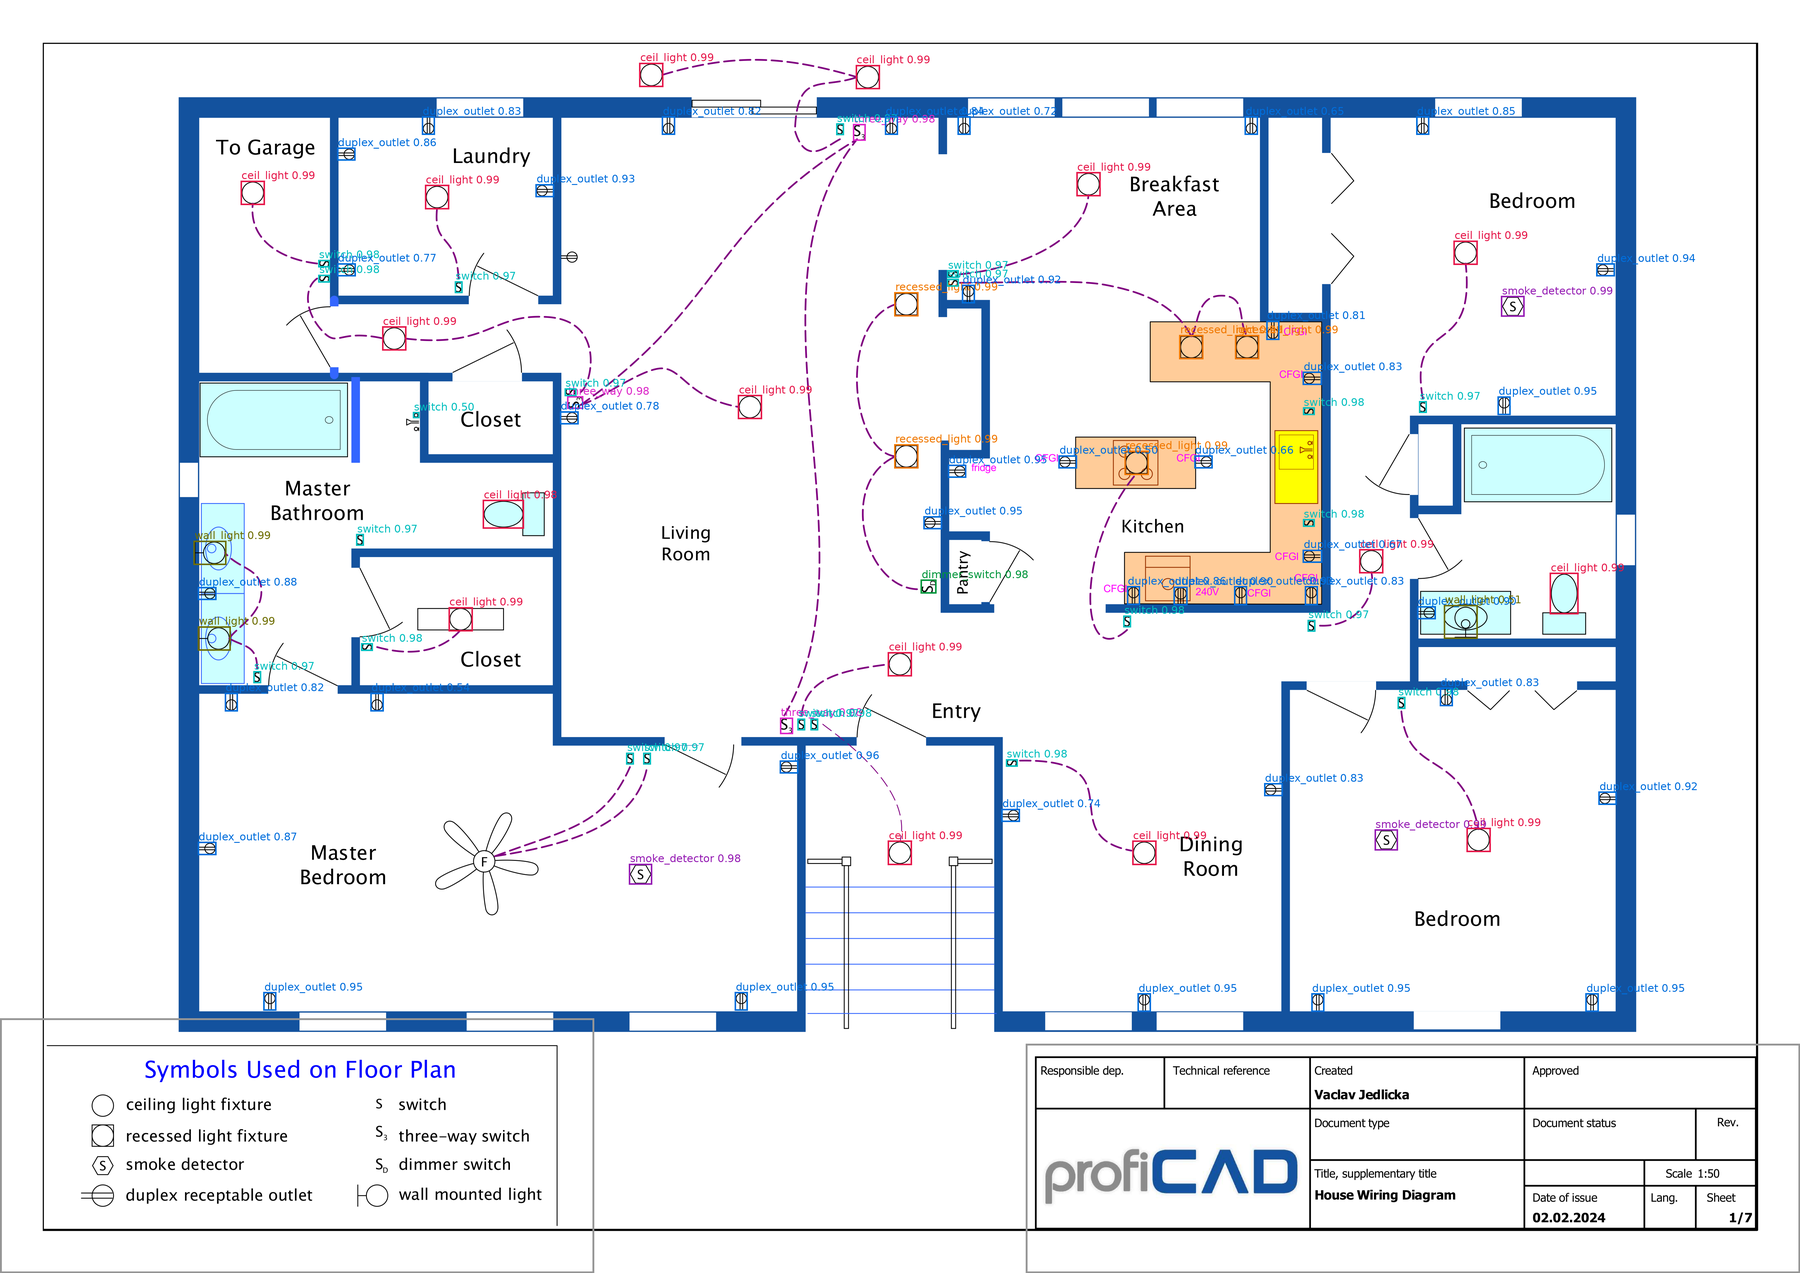

In [32]:
try:
    import pymupdf as fitz
except ImportError:
    import fitz

PLAN_PDF = "house-wiring-diagram.pdf"
BOM_NAMES = {
    "ceiling light fixture": "ceil_light",
    "recessed light fixture": "recessed_light",
    "duplex receptable outlet": "duplex_outlet",
    "wall mounted light fixture": "wall_light",
    "switch": "switch",
    "three-way switch": "three_way",
    "dimmer switch": "dimmer_switch",
}


def read_bom(pdf_path):
    doc = fitz.open(pdf_path)
    lines = []
    for i in range(3, min(6, len(doc))):
        lines += [l.strip() for l in doc[i].get_text().splitlines()]
    return {cls: lines.count(txt) for txt, cls in BOM_NAMES.items()}


BOM = read_bom(PLAN_PDF)


def in_ignored(d, W, H):
    cx, cy = (d[0] + d[2]) / 2 / W, (d[1] + d[3]) / 2 / H
    return any(a <= cx <= c and b <= cy <= e for a, b, c, e in IGNORE)


def report(threshold=0.5):
    H, W = plan_img.shape[:2]
    dets = [d for d in all_dets if d[4] >= threshold]
    used = [d for d in dets if not in_ignored(d, W, H)]
    print(f"confidence >= {threshold}: {len(used)} detections counted, "
          f"{len(dets) - len(used)} ignored (legend and title block)")
    print(f"\n{'class':18s}{'plan list':>10s}{'found':>7s}{'difference':>12s}")
    for cid in range(len(class_names)):
        name = class_names[cid]
        n = sum(1 for d in used if d[5] == cid)
        b = BOM.get(name)
        diff = "-" if b is None else f"{n - b:+d}"
        print(f"{name:18s}{('-' if b is None else b):>10}{n:>7d}{diff:>12s}")
    print("\nnot trained: fan (1), fluorescent light (1), 240 V outlet (1, may be counted as a duplex outlet)")

    img = Image.fromarray(cv2.cvtColor(plan_img, cv2.COLOR_BGR2RGB))
    d = ImageDraw.Draw(img)
    font = get_font(34)
    for a, b, c, e in IGNORE:
        d.rectangle([a * W, b * H, c * W, e * H], outline=(150, 150, 150), width=6)
    for x0, y0, x1, y1, s, cid in used:
        col = PALETTE[cid % len(PALETTE)]
        d.rectangle([x0 - 3, y0 - 3, x1 + 3, y1 + 3], outline=col, width=5)
        d.text((x0, max(0, y0 - 40)), f"{class_names[cid]} {s:.2f}", fill=col, font=font)
    img.save("plan_detected.png")
    return img


def view(img, region=(0, 0, 1, 1), width=1800):
    W, H = img.size
    crop = img.crop((int(region[0] * W), int(region[1] * H), int(region[2] * W), int(region[3] * H)))
    s = min(1.0, width / crop.size[0])
    display(crop.resize((int(crop.size[0] * s), int(crop.size[1] * s)), Image.LANCZOS))


result = report(0.5)
view(result)

In [34]:
def box_dims(boxes):
    return np.array([sorted((b[2] - b[0], b[3] - b[1])) for b in boxes])


def scale_check(threshold=0.5):
    H, W = plan_img.shape[:2]
    truth = {i: [] for i in range(len(class_names))}
    for p in glob.glob(os.path.join(OUT_DIR, "labels", "val", "*.txt")):
        for line in open(p).read().splitlines():
            if line.strip():
                c, xc, yc, w, h = line.split()
                truth[int(c)].append((0, 0, float(w) * TILE, float(h) * TILE))
    found = {i: [] for i in range(len(class_names))}
    for d in all_dets:
        if d[4] >= threshold and not in_ignored(d, W, H):
            found[d[5]].append(d)
    print("box size in pixels, short side x long side")
    print(f"{'class':18s}{'validation images':>20s}{'real plan':>16s}{'ratio':>8s}")
    for cid in range(len(class_names)):
        if not truth[cid] or not found[cid]:
            continue
        a = box_dims(truth[cid]).mean(axis=0)
        b = box_dims(found[cid]).mean(axis=0)
        print(f"{class_names[cid]:18s}{a[0]:>9.0f} x {a[1]:<8.0f}{b[0]:>7.0f} x {b[1]:<6.0f}{b[1] / a[1]:>8.2f}")


scale_check()

box size in pixels, short side x long side
class                validation images       real plan   ratio
ceil_light               72 x 72           74 x 79        1.10
dimmer_switch            37 x 46           38 x 45        0.98
duplex_outlet            71 x 105          36 x 54        0.51
recessed_light           71 x 72           72 x 72        1.01
smoke_detector           60 x 69           61 x 69        1.01
switch                   19 x 32           19 x 31        0.99
three_way                35 x 47           35 x 47        1.00
wall_light               72 x 99           82 x 101       1.01
